# Patient Variation

Predicting patient outcomes from biomarkers

In [34]:
import os
import sys
import numpy as np
import pandas as pd
import scipy as sc
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import (convert_ode_parameters, ExtractTreatmentFromDf,  GetPatientIDs, calc_delta_benefit, predict_drug_benefit, predict_ct_ttp, LoadPatientData)
from plotUtils import PlotDrug, PlotSimulation, convert_to_rgb_grayscale
from odeModels import LotkaVolterraModel

In [35]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_58655/884701199.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([''] + list(colors.keys()));


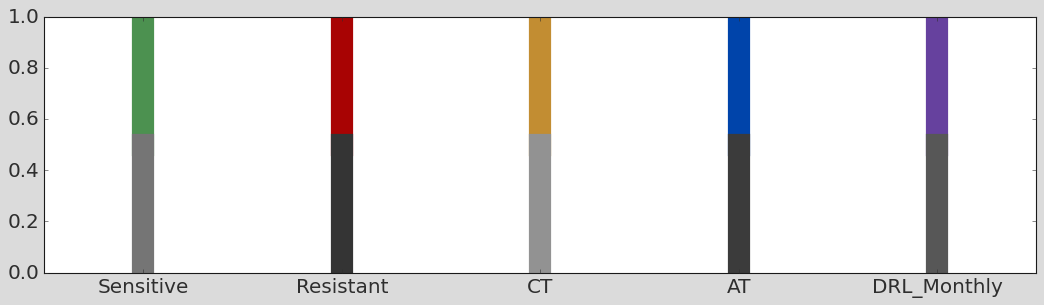

In [36]:
# Defaults for plotting
colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

fig, ax = plt.subplots(1, 1, figsize=(16, 4))
for i, col in enumerate(colors.values()):
    plt.axvline(i+1, 0.5, 1, color = col, linewidth=20)
    plt.axvline(i+1, 0, 0.5, color = convert_to_rgb_grayscale(col), linewidth=20)
plt.xlim(0.5, len(colors.values()) + 0.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().set_xticklabels([''] + list(colors.keys()));

In [37]:
file_path = os.path.dirname(os.path.abspath("__file__"))

out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Prog_fits")

In [38]:
def SimulateFit(fit_params, dataDf, dt=1, solver_kws={}):
    myModel = LotkaVolterraModel()
    myModel.SetParams(**fit_params)
    myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
    # Interpolate to the desired time grid
    t_eval = np.arange(0, myModel.resultsDf.Time.max(), dt)
    trimmedResultsDic = {'Time': t_eval}
    for variable in ['S', 'R', 'TumourSize', 'DrugConcentration']:
        f = sc.interpolate.interp1d(myModel.resultsDf.Time, myModel.resultsDf[variable])
        trimmedResultsDic = {**trimmedResultsDic, variable: f(t_eval)}
    myModel.resultsDf = pd.DataFrame(trimmedResultsDic)
    return myModel

In [39]:
def Plot_method(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_color = 'k', colors = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    linestyles = ['-', '--', '--']
    for i, var in enumerate(["TumourSize", 'S', 'R']):
        ax.plot(df['Time'], df[var], linewidth=linewidth, linestyle=linestyles[i], color=colors[var], **kwargs)

    PlotDrug(df, ax, drug_color, plotDrugAsBar = True, currDrugBarPosition = 1.25)

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    ax.yaxis.get_major_ticks()[-1].set_visible(False); ax.tick_params(right = False, top = False)

## Patient Datasets

In [40]:
data_path = "../patients/Bruchovsky_et_al/Prog_data_txt"

# Load the data
df = pd.read_csv("patient_fits/full_history_params.csv")
trunc_df = pd.read_csv("patient_fits/first_cycle_params.csv")

patientIds = pd.merge(df[['PatientId']], trunc_df[['PatientId']], 
                      on='PatientId')['PatientId'].unique()

n = len(df['PatientId'].unique())
cols = [colormaps['tab10'](i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd',]

## Predicted benefit of Adaptive Therapy

[0 1 2 3 4] [np.float64(0.2907009661269058), np.float64(0.46515478212261463), np.float64(0.43786408246628156), np.float64(0.43900654686131946), np.float64(0.9404902600537353)]
[0 1 2 3 4] [np.float64(0.2700909253151284), np.float64(0.4953193110992137), np.float64(0.4389907783583374), np.float64(0.5517269224670636), np.float64(0.3663949670878392)]


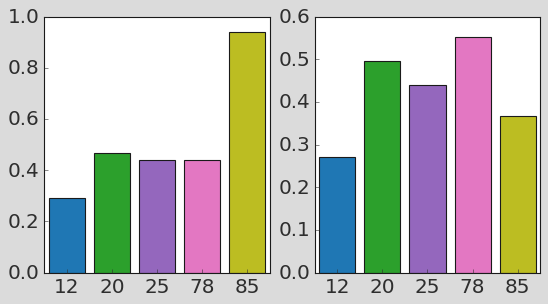

In [41]:
plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(1,2,figsize=(8,4))

ids = np.array(range(len(df.PatientId)))

for ax, df_n in zip(axs, [df, trunc_df]):
  doubling = [calc_delta_benefit(kappa=0.2, \
     **df_n[df_n.PatientId == n].iloc[0].to_dict()) 
       for n in df_n.PatientId]
  print(ids, doubling)
  ax.bar(ids, doubling, color=cols, width=0.8)
  ax.set_xticks(ids, df_n.PatientId)
      
  ax.set_xlim(-0.5, 4.5), ax.set_ylim(bottom=0); 
  ax.tick_params(top=False, right=False)
# ax.set_xlabel("Patient ID"); ax.set_ylabel("Crit Threshold (days)"); 
# plt.legend(loc=1, fontsize=14, numpoints=1)
# plt.gca().legend(loc=1, fontsize=18, numpoints=1).get_frame().\
  # set_boxstyle('Round', pad=0.2, rounding_size=0.5)

In [42]:
def calc_ttp(row, method='ROT'):
    model = LotkaVolterraModel()
    model.SetParams(**row.to_dict())
    return model.CalcTtp(updating_interval=1, method=method)

trial_times = df.sort_values(by=['PatientId']).TimeInTrial.values
perfect_at_list = [calc_ttp(df[df.PatientId == n].iloc[0]) for n in df.PatientId.values]
at_over_trial_list = [(j-i)/i for i, j in zip(trial_times, perfect_at_list)]

ct_list = [calc_ttp(df[df.PatientId == n].iloc[0], method='MTD') for n in df.PatientId.values]
trial_over_ct_list = [(j-i)/i for i, j in zip(ct_list, trial_times)]
at_over_ct_list = [(j-i)/i for i, j in zip(ct_list, perfect_at_list)]

In [43]:
print("AT over trial: ", at_over_trial_list)

AT over trial:  [np.float64(-0.11339460539461702), np.float64(0.2547674731182781), np.float64(0.13736812411846358), np.float64(0.4088249813014105), np.float64(0.10694642857140073)]


In [44]:
def regression_plot_unstyled(x_vals, y_vals, ax, xlabel, ylabel, title):
    ax.scatter(x_vals, y_vals, color='black')
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.plot(np.unique(x_vals), np.poly1d(np.polyfit(x_vals, y_vals, 1))(np.unique(x_vals)), color='black')

In [45]:
def regression_plot(x_vals, y_vals, ax, xlabel, ylabel, title, use_percent=True, cols=None, markers=None):
    if cols is None: cols = ['k'] * len(x_vals)
    if markers is None: markers = ['o'] * len(x_vals)
    for n, (x, y) in enumerate(zip(x_vals, y_vals)):
        ax.scatter(x, y, color=cols[n], marker=markers[n], s=100)
    
    slope, intercept = np.polyfit(x_vals, y_vals, 1)
    line_sim = slope * np.array(x_vals) + intercept
    ax.plot(sorted(x_vals), sorted(line_sim), color=colors['CT'], linestyle='--')
    
    r2_sim = np.corrcoef(x_vals, y_vals)[0, 1] ** 2
    ax.annotate(f"$R^{2} = {r2_sim:.2f}$", xy=(0.05, 0.85), xycoords='axes fraction', fontsize=22)
    ax.tick_params(top=False, right=False);
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.set_xticks(ax.get_xticks()[::2]); ax.set_yticks(ax.get_yticks()[::2]); 
    if min(y_vals) > 0:
        ax.set_ylim(bottom=0)

    if use_percent:
        ax.set_yticklabels([f"{int(x*100)}" for x in ax.get_yticks()])
        ax.set_xticklabels([f"{int(x*100)}" for x in ax.get_xticks()])

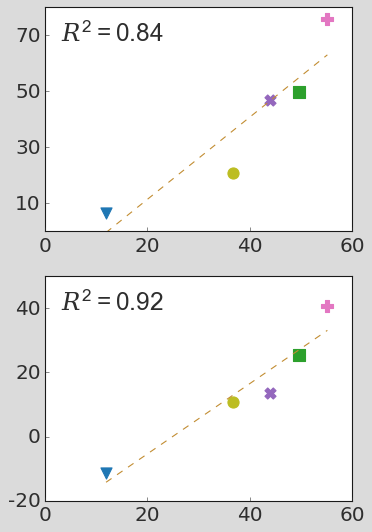

In [46]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(2,1 ,figsize=(5,7))
    
def doubling_benefit_wrapper(row):
    kappa = 0.5 * row.n0 / row.K  # 50% threshold, accounting for kappa scaling
    return calc_delta_benefit(kappa=kappa, **row.to_dict())
  
doubling = [doubling_benefit_wrapper(trunc_df[trunc_df.PatientId == n].iloc[0])
            for n in trunc_df.PatientId]

plot_args = {'cols': cols, 'markers': markers}
regression_plot(doubling, at_over_ct_list, ax[0], "", "", "", **plot_args)
regression_plot(doubling, at_over_trial_list, ax[1], "", "", "", **plot_args)

plt.tight_layout()
# plt.savefig("figures/fig3_doubling_prediction.pdf")

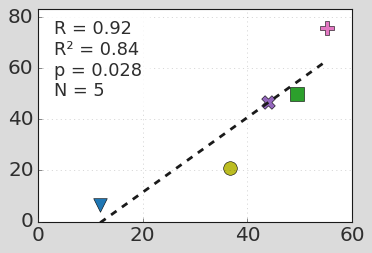

In [47]:
from scipy.stats import linregress, pearsonr

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(5, 3.5))

x_vals = np.array(doubling)
y_vals = np.array(at_over_ct_list)

# Plot points colored by patient
for i, patientId in enumerate(trunc_df['PatientId']):
    ax.scatter(x_vals[i], y_vals[i], color=cols[i], marker=markers[i], s=150, 
               label=f'Patient {patientId}', edgecolor='black', linewidth=0.5)

# Linear regression
if len(x_vals) >= 2 and np.std(x_vals) > 0:
    fit = linregress(x_vals, y_vals)
    xline = np.linspace(np.nanmin(x_vals), np.nanmax(x_vals), 100)
    yline = fit.slope * xline + fit.intercept
    ax.plot(xline, yline, color='k', linestyle='--', linewidth=2.5, label='Linear fit')
    
    r, p = pearsonr(x_vals, y_vals)
    ax.annotate(f"R = {r:.2f}\nR² = {r**2:.2f}\np = {p:.3f}\nN = {len(x_vals)}", 
                xy=(0.05, 0.95), xycoords='axes fraction',
                ha='left', va='top', fontsize=16,
                bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='none', alpha=0.8))

# ax.set_xlabel('Doubling Benefit (τ=50%)')
# ax.set_ylabel('AT/CT TTP Ratio')
# ax.set_title('Adaptive Therapy Benefit vs Doubling Benefit')
ax.tick_params(top=False, right=False)
ax.grid(alpha=0.3)
ax.set_ylim(0, max(y_vals)*1.1)
ax.set_xticks(ax.get_xticks()[::2]); ax.set_xticklabels([f"{int(x*100)}" for x in ax.get_xticks()])
ax.set_yticks(ax.get_yticks()[::2]); ax.set_yticklabels([f"{int(y*100)}" for y in ax.get_yticks()])

plt.tight_layout()
plt.savefig("figures/fig3_doubling_prediction.pdf")
plt.show()

## TTP Prediction

Can this metric predict CT and AT50? 

In [48]:
import math

def calc_threshold_benefit(n_crit, **kwargs):
    params = kwargs
    ave_n = (n_crit + params['n0'])/2
    return calc_delta_benefit(kappa=(ave_n / params['K']), **params)

def predict_at50_ttp(**kwargs):
    params = kwargs
    benefit = calc_threshold_benefit(0.5 * params['n0'], **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

In [49]:
def sim_ct_ttp(params):
    model = LotkaVolterraModel()
    model.SetParams(**params)
    model.Simulate([[0, 3000, 1]]); model.Trim()
    return model.resultsDf[model.resultsDf.TumourSize < params['n0']*1.2].Time.max()

In [50]:
# Generate a table with patient id, predicted CT TTP
TTP_data = []
param_sets = [trunc_df, df]

for patientId in tqdm(patientIds):
    param_sets = [trunc_df.loc[trunc_df.PatientId == patientId].iloc[0].to_dict(),
                  df.loc[df.PatientId == patientId].iloc[0].to_dict()]
    
    ct_preds = [predict_ct_ttp(**param_set) for param_set in param_sets]
    ct_sims = [int(sim_ct_ttp(param_set)) for param_set in param_sets]
    
    
    TTP_data.append([patientId, *ct_preds, *ct_sims])

ct_ttp_df = pd.DataFrame(TTP_data, columns=['PatientId', 'TruncPrediction', 'FullPrediction',
                                                   'TruncSimulation', 'FullSimulation'])
print(ct_ttp_df)

100%|██████████| 5/5 [00:04<00:00,  1.08it/s]

   PatientId  TruncPrediction  FullPrediction  TruncSimulation  FullSimulation
0         12       524.628458      810.897291              540             833
1         20       905.119579     1186.411470              937            1246
2         25       816.810549     1061.688373              848            1098
3         78       996.045475     1026.796622             1029            1072
4         85       702.186978      645.346864              734             666


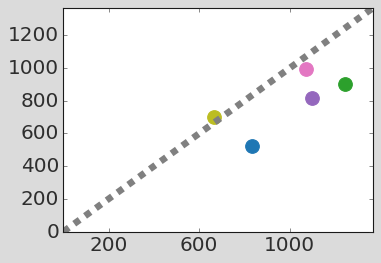

In [51]:
scale_extension = 1.1

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(5, 3.5))
for i, patientId in enumerate(ct_ttp_df['PatientId']):
    ax.scatter(ct_ttp_df.loc[ct_ttp_df['PatientId'] == patientId, 'FullSimulation'],
               ct_ttp_df.loc[ct_ttp_df['PatientId'] == patientId, 'TruncPrediction'],
               color=cols[i], s=150, label=f'Patient {patientId}')
max_time = max(ct_ttp_df['FullSimulation'].max(), 
               ct_ttp_df['TruncPrediction'].max())
ax.plot([0, max_time * scale_extension], [0, max_time*scale_extension], 
        linestyle='--', linewidth=6, color='gray', label='Guide Line')

ax.set_xticks(ax.get_xticks()[::2])
# ax.set_xlabel('True Doubling Time'); ax.set_ylabel('Predicted Doubling Time')
ax.set_xlim(0, max_time*scale_extension); ax.set_ylim(0, max_time*scale_extension)
# ax.legend(loc=2)
plt.savefig("figures/fig3_ct_prediction_comparison.pdf", dpi=300, bbox_inches='tight')

In [52]:
def sim_at50_ttp(params, threshold=0.5):
    model = LotkaVolterraModel()
    model.SetParams(**params)
    model.Simulate_AT(atThreshold=threshold * params['n0'], atMethod='Zhang',
                intervalLength=1, t_end=6000, refSize = params['n0'])
    model.Trim()
    return model.resultsDf[model.resultsDf.TumourSize < params['n0']*1.2].Time.max()

In [53]:
# Generate a table with patient id, predicted AT TTP
TTP_data = []
param_sets = [trunc_df, df]

for patientId in tqdm(patientIds):
    param_sets = [trunc_df.loc[trunc_df.PatientId == patientId].iloc[0].to_dict(),
                  df.loc[df.PatientId == patientId].iloc[0].to_dict()]
    
    at_preds = [int(predict_at50_ttp(**param_set)) for param_set in param_sets]
    at_sims = [int(sim_at50_ttp(param_set)) for param_set in param_sets]
    
    
    TTP_data.append([patientId, *at_preds, *at_sims])

at_ttp_df = pd.DataFrame(TTP_data, columns=['PatientId', 'TruncPrediction', 'FullPrediction',
                                                   'TruncSimulation', 'FullSimulation'])
print(at_ttp_df)

100%|██████████| 5/5 [00:56<00:00, 11.31s/it]

   PatientId  TruncPrediction  FullPrediction  TruncSimulation  FullSimulation
0         12              624             927              600             863
1         20             1798            2132             1596            1697
2         25             1505            1759             1363            1612
3         78             2134            2179             1853            1740
4         85             1174             994             1079             809


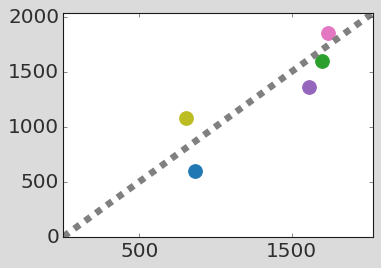

In [54]:
scale_extension = 1.1

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(5, 3.5))
for i, patientId in enumerate(at_ttp_df['PatientId']):
    ax.scatter(at_ttp_df.loc[at_ttp_df['PatientId'] == patientId, 'FullSimulation'],
               at_ttp_df.loc[at_ttp_df['PatientId'] == patientId, 'TruncSimulation'],
               color=cols[i], s=150, label=f'Patient {patientId}')
max_time = max(at_ttp_df['FullSimulation'].max(), 
               at_ttp_df['TruncSimulation'].max())
ax.plot([0, max_time * scale_extension], [0, max_time*scale_extension], 
        linestyle='--', linewidth=6, color='gray', label='Guide Line')

ax.set_xticks(ax.get_xticks()[::2])
# ax.set_xlabel('True Doubling Time'); ax.set_ylabel('Predicted Doubling Time')
ax.set_xlim(0, max_time*scale_extension); ax.set_ylim(0, max_time*scale_extension)
# ax.legend(loc=2)
plt.savefig("figures/fig3_at_prediction_comparison.pdf", dpi=300, bbox_inches='tight')

In [55]:
print(patientIds)

[12 20 25 78 85]


1it [00:01,  1.71s/it]

Patient 85: Diff of -71 days (-8.89%)


2it [00:03,  2.00s/it]

Patient 12: Diff of -22 days (-2.55%)


3it [00:09,  3.85s/it]

Patient 25: Diff of -26 days (-1.61%)


4it [00:16,  4.88s/it]

Patient 20: Diff of 113 days (6.71%)


5it [00:23,  4.64s/it]

Patient 78: Diff of 153 days (8.80%)


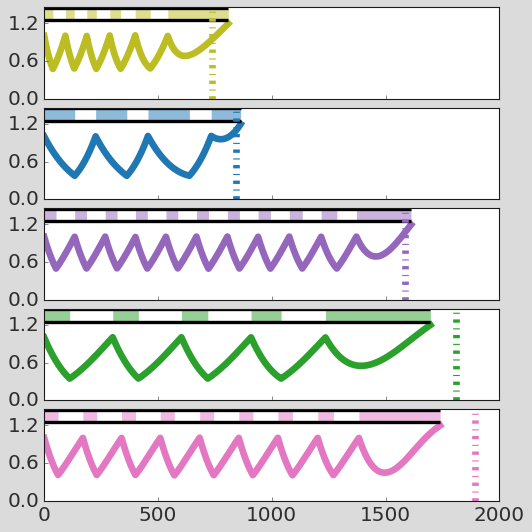

In [56]:

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(5, 1, figsize=(7, 7), sharex=True)

at_ttp_df = at_ttp_df.sort_values(by='FullSimulation')

for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    model = LotkaVolterraModel(); model.SetParams(**params)
    
    # model.Simulate([[0, 3000, 1]]); model.CleanData()
    # ct_ttp = model.resultsDf[model.resultsDf.TumourSize < params['n0']*1.2].Time.max()
    # ax[i].vlines(ct_ttp, 0, 1.25, color='gray', linestyle='--', linewidth=6, zorder=-1)
    
    model.Simulate_AT(atThreshold=0.5 * params['n0'], atMethod='Zhang',
                intervalLength=1, t_end=6000, refSize = params['n0'])
    model.CleanData()
    
    patient_index = np.where(patientIds == patientId)[0][0]
    palette = {'TumourSize': cols[patient_index], 'S': None, 'R': None}
    
    PlotSimulation(model.resultsDf, ax=ax[i], colors=palette, linewidth=6, plot_subpops=False, 
                   drug_col=cols[patient_index], prog_line=False)
    ax[i].set_yticks(ax[i].get_yticks()[::3])
    
    prediction = predict_at50_ttp(upper = params['n0'] * 0.2, n_lim = params['n0']*0.6, **params)
    # prediction = at_ttp_df.loc[at_ttp_df['PatientId'] == patientId]['TruncPrediction'].values[0]
    ax[i].axvline(prediction, color=cols[patient_index], linestyle='-.', linewidth=6)
    ax[i].set_ylim(0, 1.46)
    
    print(f"Patient {patientId}: Diff of {int(prediction - model.resultsDf.Time.max())} days" + 
          f" ({(prediction - model.resultsDf.Time.max()) / model.resultsDf.Time.max() * 100:.2f}%)")

ax[-1].set_xlim(0, 2000)    
fig.subplots_adjust(hspace=0.1)
plt.savefig("figures/fig3_at_predictions.pdf", dpi=300, bbox_inches='tight')


In [57]:
for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    # True Parameter Simulation
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    model = LotkaVolterraModel(); model.SetParams(**params)
    
    model.Simulate_AT(atThreshold=0.5 * params['n0'], atMethod='Zhang',
                intervalLength=1, t_end=6000, refSize = params['n0'])
    model.CleanData()
    true_sim_ttp = model.resultsDf.Time.max()
    
    # Trunc Parameter Simulation
    trunc_params = trunc_df[trunc_df.PatientId == patientId].iloc[0].to_dict()
    trunc_model = LotkaVolterraModel(); trunc_model.SetParams(**trunc_params)
    
    trunc_model.Simulate_AT(atThreshold=0.5 * trunc_params['n0'], atMethod='Zhang',
                intervalLength=1, t_end=6000, refSize = trunc_params['n0'])
    trunc_model.CleanData()
    trunc_sim_ttp = trunc_model.resultsDf.Time.max()
    
    # Comparison to Prediction
    prediction = predict_at50_ttp(upper = params['n0'] * 0.2, n_lim = params['n0']*0.6, **params)
    # prediction = at_ttp_df.loc[at_ttp_df['PatientId'] == patientId]['TruncPrediction'].values[0]
    
    print(f"Patient {patientId}: True - {true_sim_ttp}, Trunc - {trunc_sim_ttp}, Prediction - {prediction}")
    print(f"    Prediction Diff of {int(prediction - true_sim_ttp)} days ({(prediction - true_sim_ttp) / true_sim_ttp * 100:.2f}%), " + 
          f"Simulation Diff of {int(trunc_sim_ttp - true_sim_ttp)} days ({(trunc_sim_ttp - true_sim_ttp) / true_sim_ttp * 100:.2f}%)")


1it [00:04,  4.84s/it]

Patient 85: True - 809.0, Trunc - 1079.0, Prediction - 737.040423976047
    Prediction Diff of -71 days (-8.89%), Simulation Diff of 270 days (33.37%)


2it [00:08,  3.86s/it]

Patient 12: True - 863.0, Trunc - 600.0, Prediction - 840.9683009825432
    Prediction Diff of -22 days (-2.55%), Simulation Diff of -263 days (-30.48%)


3it [00:17,  6.64s/it]

Patient 25: True - 1612.0, Trunc - 1363.0, Prediction - 1585.9976582679276
    Prediction Diff of -26 days (-1.61%), Simulation Diff of -249 days (-15.45%)


4it [00:29,  8.71s/it]

Patient 20: True - 1697.0, Trunc - 1596.0, Prediction - 1810.8666915222493
    Prediction Diff of 113 days (6.71%), Simulation Diff of -101 days (-5.95%)


5it [00:44,  8.95s/it]

Patient 78: True - 1740.0, Trunc - 1853.0, Prediction - 1893.143746113442
    Prediction Diff of 153 days (8.80%), Simulation Diff of 113 days (6.49%)


## Drug Metric

In [58]:
def drop_last_full_drug_period(results_df, drug_col='DrugConcentration', on_value=1.0):
    dc = results_df[drug_col].to_numpy()
    is_on = np.isclose(dc, on_value)

    if not is_on.any():
        return results_df

    last_on_idx = np.where(is_on)[0][-1]
    start_idx = last_on_idx
    while start_idx > 0 and is_on[start_idx - 1]:
        start_idx -= 1

    return results_df.drop(
        results_df.index[start_idx:last_on_idx + 1]
    ).reset_index(drop=True)

In [59]:
true_values = []
predicted_values = []
trunc_values = []

for i, patientId in enumerate(patientIds):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    model = LotkaVolterraModel(); model.SetParams(**params)
    
    model.Simulate_AT(atThreshold=0.5 , atMethod='Zhang',
                intervalLength=1, t_end=6000, refSize = params['n0'])
    model.CleanData()

    # Remove the last treatment period
    average_drug_conc = model.resultsDf['DrugConcentration'].mean()
    model.resultsDf = drop_last_full_drug_period(model.resultsDf)

    average_drug_conc = model.resultsDf['DrugConcentration'].mean()
    true_values.append(average_drug_conc)
    

    drug_prediction = predict_drug_benefit(tau=0, n_crit = params['n0']*0.5, **params)
    trunc_params = trunc_df[trunc_df.PatientId == patientId].iloc[0].to_dict()
    trunc_drug_prediction = predict_drug_benefit(tau=0, n_crit = trunc_params['n0']*0.5, **trunc_params)

    predicted_values.append(drug_prediction)
    trunc_values.append(trunc_drug_prediction)

    print(f"Patient {patientId}: Predicted - {drug_prediction:.2f}, Trunc Predicted - {trunc_drug_prediction:.2f}, Measured - {average_drug_conc:.2f}")

Patient 12: Predicted - 0.59, Trunc Predicted - 0.62, Measured - 0.60
Patient 20: Predicted - 0.34, Trunc Predicted - 0.30, Measured - 0.38
Patient 25: Predicted - 0.37, Trunc Predicted - 0.35, Measured - 0.40
Patient 78: Predicted - 0.32, Trunc Predicted - 0.26, Measured - 0.35
Patient 85: Predicted - 0.40, Trunc Predicted - 0.44, Measured - 0.42


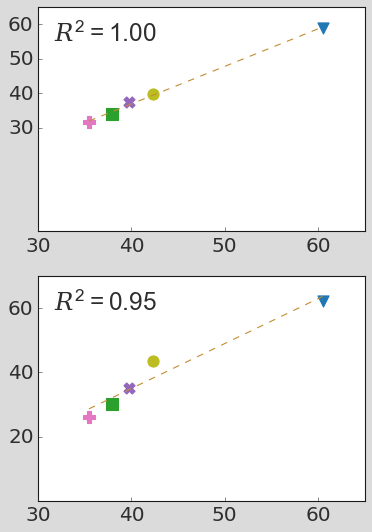

In [60]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(2,1 ,figsize=(5,7))

plot_args = {'cols': cols, 'markers': markers}
regression_plot(true_values, predicted_values, ax[0], "", "", "", **plot_args)
regression_plot(true_values, trunc_values, ax[1], "", "", "", **plot_args)

# for ax in ax:
#     ax.plot([0, 1], [0, 1], transform=ax.transAxes, linestyle='--', color='gray', linewidth=2)

plt.tight_layout()
# plt.savefig("figures/fig3_meandrug_prediction.pdf")

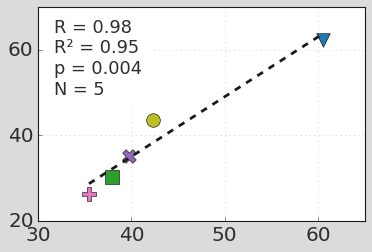

In [61]:
from scipy.stats import linregress, pearsonr

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(5, 3.5))

# x: measured MDD-like quantity, y: prediction from truncated-fit parameters
x_vals = np.array(true_values, dtype=float)
y_vals = np.array(trunc_values, dtype=float)

# Plot points colored by patient
for i, patientId in enumerate(patientIds):
    ax.scatter(
        x_vals[i], y_vals[i],
        color=cols[i], marker=markers[i], s=150,
        label=f'Patient {patientId}',
        edgecolor='black', linewidth=0.5
    )

# Linear regression
if len(x_vals) >= 2 and np.std(x_vals) > 0:
    fit = linregress(x_vals, y_vals)
    xline = np.linspace(np.nanmin(x_vals), np.nanmax(x_vals), 100)
    yline = fit.slope * xline + fit.intercept
    ax.plot(xline, yline, color='k', linestyle='--', linewidth=2.5, label='Linear fit')

    r, p = pearsonr(x_vals, y_vals)
    ax.annotate(
        f"R = {r:.2f}\nR² = {r**2:.2f}\np = {p:.3f}\nN = {len(x_vals)}",
        xy=(0.05, 0.95), xycoords='axes fraction',
        ha='left', va='top', fontsize=16,
        bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='none', alpha=0.8)
    )

# Keep labeling style consistent with prior figure
# ax.set_xlabel('Measured MDD')
# ax.set_ylabel('Predicted MDD (truncated-fit)')
# ax.set_title('MDD Prediction from Truncated Parameters')
ax.tick_params(top=False, right=False)
ax.grid(alpha=0.3)
ax.set_xticks(ax.get_xticks()[::2]); ax.set_xticklabels([f"{int(x*100)}" for x in ax.get_xticks()])
ax.set_yticks(ax.get_yticks()[::2]); ax.set_yticklabels([f"{int(y*100)}" for y in ax.get_yticks()])
# ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig("figures/fig3_mdd_trunc_prediction.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [62]:
trial_values = []
trunc_values = []

for i, patientId in enumerate(patientIds):
    dataDf = LoadPatientData(patientId, data_path)
    
    average_drug_conc = dataDf['DrugConcentration'].mean()

    trial_values.append(average_drug_conc)

    trunc_params = trunc_df[trunc_df.PatientId == patientId].iloc[0].to_dict()
    trunc_drug_prediction = predict_drug_benefit(tau=0, n_crit = trunc_params['n0']*0.5, **trunc_params)
    trunc_values.append(trunc_drug_prediction)

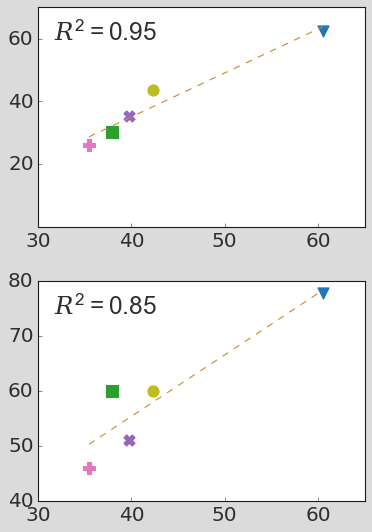

In [63]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(2,1 ,figsize=(5,7))

plot_args = {'cols': cols, 'markers': markers}
regression_plot(true_values, trunc_values, ax[0], "", "", "", **plot_args)
regression_plot(true_values, trial_values, ax[1], "", "", "", **plot_args)

# ax[0].set_xlim(0.3, 0.65); ax[0].set_ylim(0.15, 0.8)
# ax[1].set_xlim(0.3, 0.65); 
ax[1].set_ylim(0.4, 0.8)

plt.tight_layout()
# plt.savefig("figures/fig3_meandrug_prediction.pdf")